# Scalability extensions across families



In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("scalability")
sources = th.load_aligned_sources()
main = sources["benchmark_with_biological"]
archived = th.prepare_metrics(th.load_historical_benchmark())


## Accuracy and runtime curves


,scalability_family,n_nodes,model,mean,std,size
0,eb_gaussian_linear,10.0,AVICI,0.616645,0.125270,15
1,eb_gaussian_linear,10.0,DAGMA_Linear,0.268810,0.169676,15
2,eb_gaussian_linear,10.0,DAGMA_Nonlinear,0.410625,0.095681,15
3,eb_gaussian_linear,10.0,DAS,0.240082,0.131551,15
4,eb_gaussian_linear,10.0,DirectLiNGAM,0.431603,0.148130,15
5,eb_gaussian_linear,10.0,FCI,0.186958,0.157737,15
6,eb_gaussian_linear,10.0,GES,0.633949,0.198407,15
7,eb_gaussian_linear,10.0,GOLEM,0.231040,0.155613,15
8,eb_gaussian_linear,10.0,GRaSP,0.722809,0.133726,15
9,eb_gaussian_linear,10.0,GraNDAG,0.124769,0.080779,15


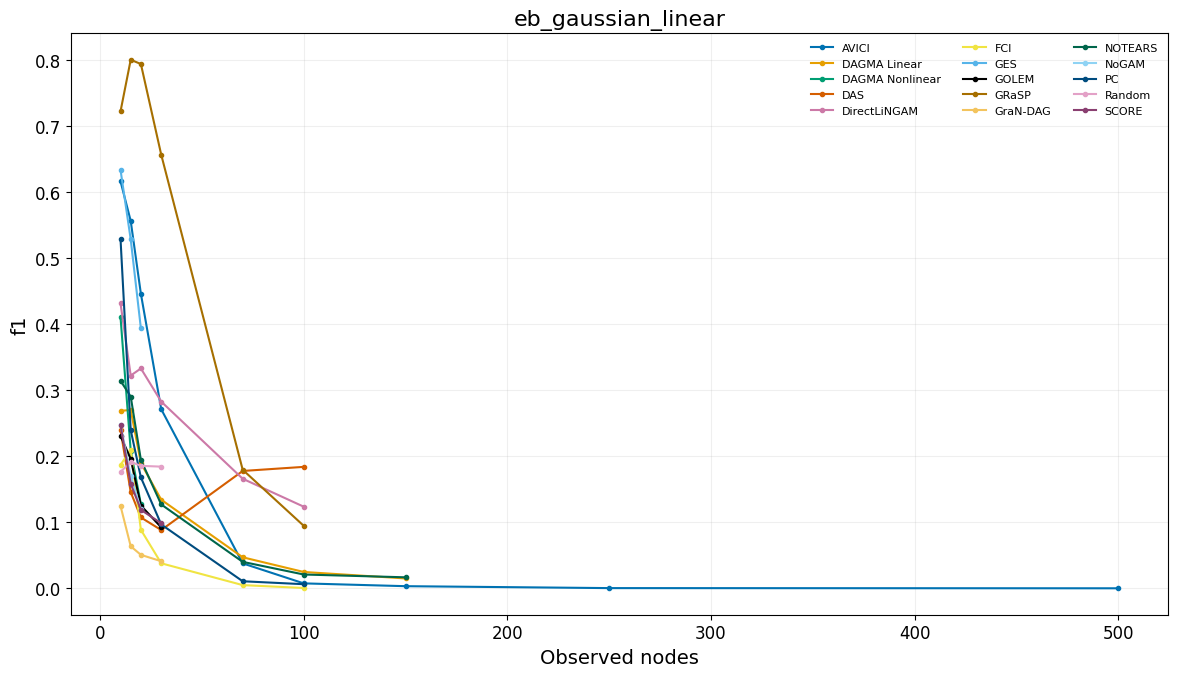

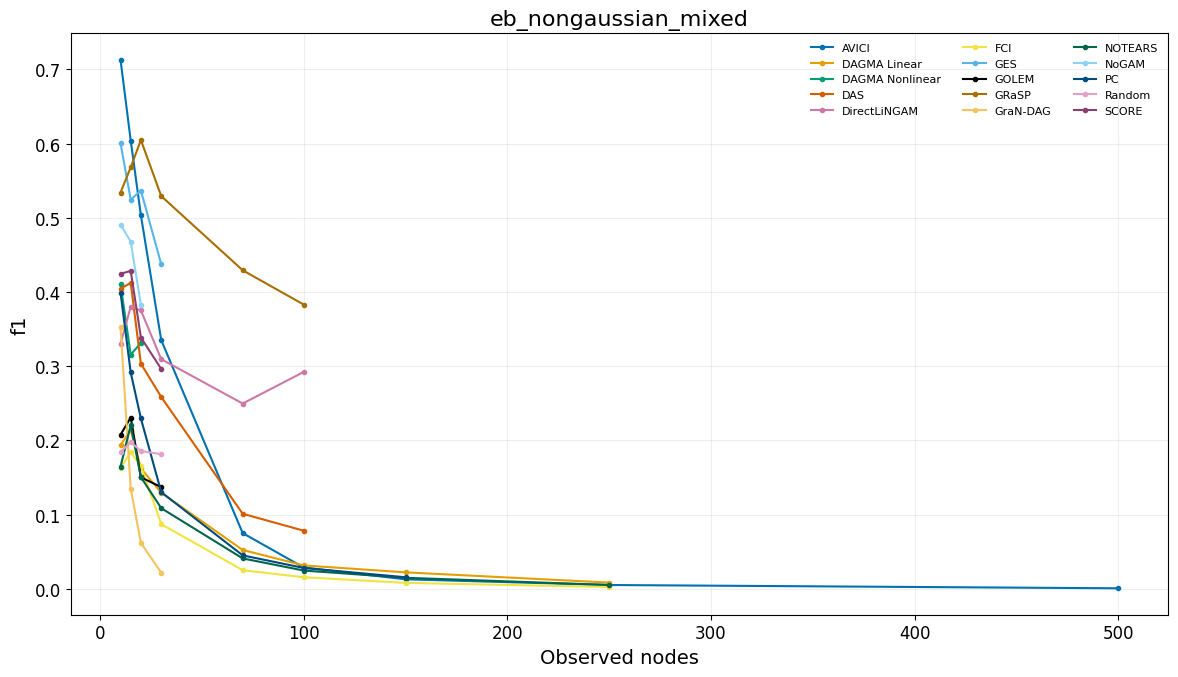

,scalability_family,n_nodes,model,mean,std,size
0,eb_gaussian_linear,10.0,AVICI,134.321636,0.699079,15
1,eb_gaussian_linear,10.0,DAGMA_Linear,12.667524,1.914128,15
2,eb_gaussian_linear,10.0,DAGMA_Nonlinear,785.668178,11.219803,15
3,eb_gaussian_linear,10.0,DAS,61.910240,0.534461,15
4,eb_gaussian_linear,10.0,DirectLiNGAM,2.429996,0.098605,15
5,eb_gaussian_linear,10.0,FCI,2.254200,0.201726,15
6,eb_gaussian_linear,10.0,GES,0.957822,0.470077,15
7,eb_gaussian_linear,10.0,GOLEM,866.290142,8.281253,15
8,eb_gaussian_linear,10.0,GRaSP,0.310916,0.068453,15
9,eb_gaussian_linear,10.0,GraNDAG,420.553671,3.202675,15


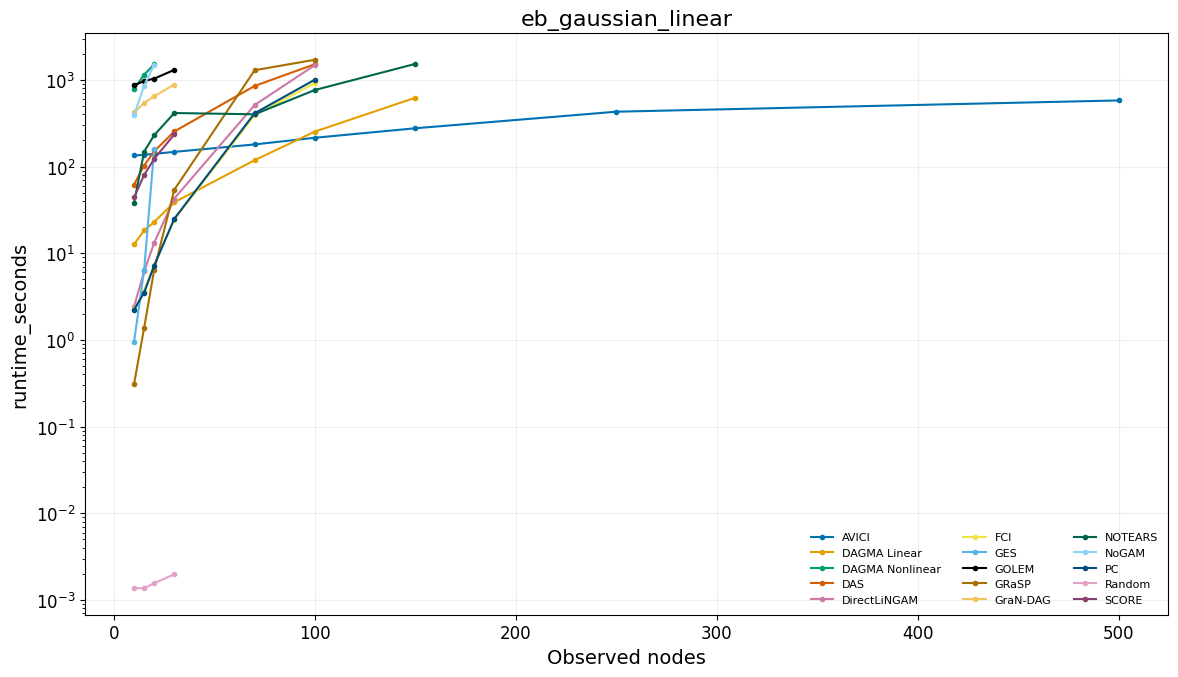

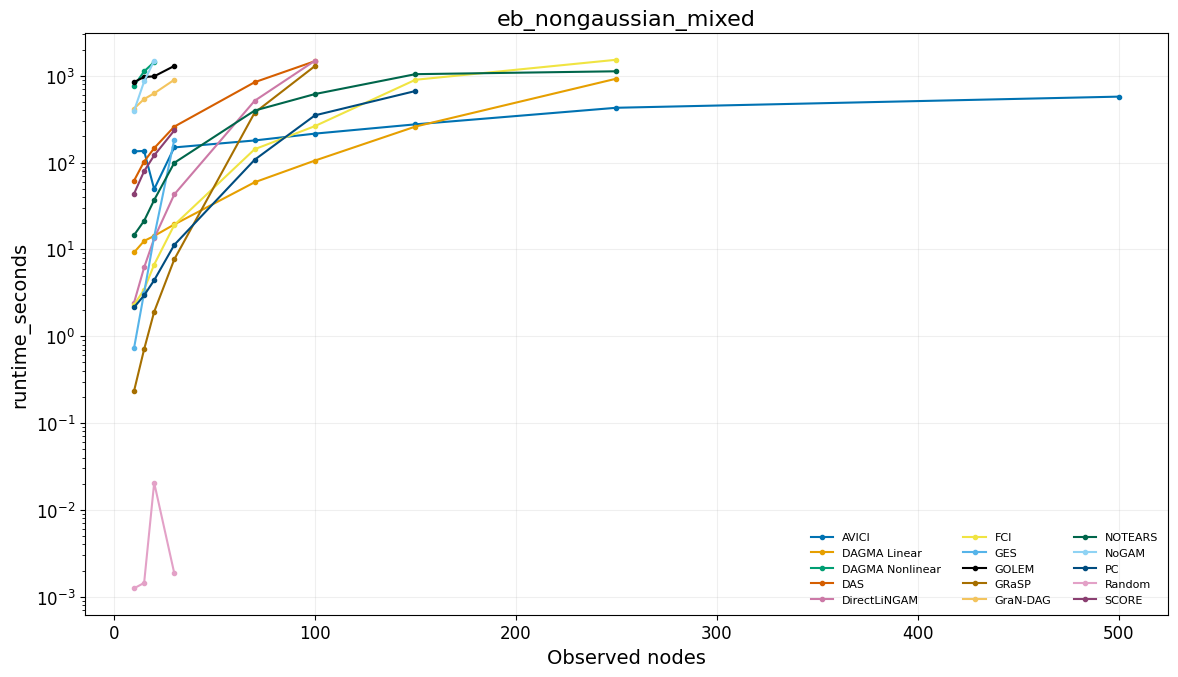

In [2]:
scalability_base = pd.concat([archived.loc[archived.n_nodes.ne(20)], main], ignore_index=True)
scale = fv.load_scalability_data(th.visualization_data(scalability_base), project_root=ROOT)
for metric in ("f1", "runtime_seconds"):
    cells = (
        scale.loc[scale.status.eq("finished")]
        .groupby(["scalability_family", "n_nodes", "dataset_seed", "model"])[metric]
        .mean()
        .reset_index()
    )
    summary = (
        cells.groupby(["scalability_family", "n_nodes", "model"])[metric]
        .agg(["mean", "std", "size"])
        .reset_index()
    )
    display(summary.head(20))
    for family, g in summary.groupby("scalability_family"):
        fig, ax = plt.subplots(figsize=(12, 7))
        for model, series in g.groupby("model"):
            series = series.sort_values("n_nodes")
            ax.plot(
                series.n_nodes,
                series["mean"],
                marker="o",
                label=th.model_label(model),
                markersize=3,
            )
        ax.set(xlabel="Observed nodes", ylabel=metric, title=family)
        if metric == "runtime_seconds":
            ax.set_yscale("log")
        ax.legend(fontsize=8, ncol=3)
        ax.grid(alpha=0.2)
        fig.tight_layout()
        fig.savefig(th.OUTPUT / f"scalability_{family}_{metric}.pdf")
        display(fig)
        plt.close(fig)
